03 · Baselines, biais–variance et méthodes d'ensemble

Étapes 5 et 6. Tous les modèles sont évalués sur les mêmes plis (`cv = make_cv()`).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inclusion_financiere.config import RANDOM_STATE, FIGURES, DECISIONS, COST_FP, COST_FN
from inclusion_financiere.data import load_raw, clean, split, make_cv, CAT_COLS, NUM_COLS

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

import json
from sklearn.model_selection import cross_validate, learning_curve, validation_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from inclusion_financiere.features import pipe
from inclusion_financiere.evaluate import summarize

In [2]:
X, y = clean(load_raw())
X_train, X_test, y_train, y_test = split(X, y)
del X_test, y_test  # test sous scellé jusqu'à l'étape 10
cv = make_cv()       # le même objet cv pour tous les modèles
print(X_train.shape, round(y_train.mean(), 4))

scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc",
           "brier": "neg_brier_score", "logloss": "neg_log_loss", "acc": "accuracy"}
resultats = {}   # nom -> dictionnaire de cross_validate


def evaluer(nom, modele):
    resultats[nom] = cross_validate(modele, X_train, y_train, cv=cv, scoring=scoring,
                                    return_train_score=True)
    return summarize(resultats[nom], nom, list(scoring))


def rapport(noms):
    t = pd.DataFrame([summarize(resultats[n], n, list(scoring)) for n in noms]).set_index("model")
    f = lambda m: t[f"{m}_val_mean"].map("{:.3f}".format) + " ± " + t[f"{m}_val_std"].map("{:.3f}".format)
    return pd.DataFrame({"PR-AUC val": f("pr_auc"), "PR-AUC train": t["pr_auc_train_mean"].round(3),
                         "ROC-AUC val": f("roc_auc"), "Brier val": f("brier"), "Accuracy val": f("acc"),
                         "Temps fit (s)": t["fit_time_mean"].round(2)})

(18819, 10) 0.1408


Étape 5 · Trois modèles de référence

In [3]:
evaluer("Dummy (most_frequent)", pipe(DummyClassifier(strategy="most_frequent")))
evaluer("LogReg sans mes variables", pipe(LogisticRegression(max_iter=2000), own_features=False))
evaluer("LogReg avec mes variables", pipe(LogisticRegression(max_iter=2000)))
evaluer("Random Forest défaut", pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                                            random_state=RANDOM_STATE)))
rapport(["Dummy (most_frequent)", "LogReg sans mes variables", "LogReg avec mes variables",
         "Random Forest défaut"])

,PR-AUC val,PR-AUC train,ROC-AUC val,Brier val,Accuracy val,Temps fit (s)
model,,,,,,
Dummy (most_frequent),0.141 ± 0.000,0.141,0.500 ± 0.000,0.141 ± 0.000,0.859 ± 0.000,0.31
LogReg sans mes variables,0.561 ± 0.029,0.566,0.849 ± 0.011,0.087 ± 0.003,0.885 ± 0.005,0.46
LogReg avec mes variables,0.559 ± 0.028,0.565,0.849 ± 0.010,0.087 ± 0.003,0.885 ± 0.005,0.48
Random Forest défaut,0.476 ± 0.040,0.986,0.805 ± 0.011,0.102 ± 0.004,0.864 ± 0.007,2.36


In [4]:
# Q5.2 : comparaison appariée, pli par pli (mêmes plis)
d = resultats["LogReg avec mes variables"]["test_pr_auc"] - resultats["LogReg sans mes variables"]["test_pr_auc"]
print("Différences de PR-AUC par pli :", d.round(4))
print(f"Moyenne {d.mean():+.4f} ± {d.std(ddof=1):.4f}")

Différences de PR-AUC par pli : [-0.0005  0.     -0.0023 -0.0006 -0.0039]
Moyenne -0.0015 ± 0.0016


Q5.1 — Résultats en validation croisée (5 plis) :

| Modèle | PR-AUC | ROC-AUC | Brier | Accuracy | Temps fit (s) |
|---|---|---|---|---|---|
| Dummy (most_frequent) | 0,141 ± 0,000 | 0,500 ± 0,000 | 0,141 ± 0,000 | 0,859 ± 0,000 | 0,3 |
| LogReg sans mes variables | 0,561 ± 0,029 | 0,849 ± 0,011 | 0,087 ± 0,003 | 0,885 ± 0,005 | 0,5 |
| LogReg avec mes variables | 0,559 ± 0,028 | 0,849 ± 0,010 | 0,087 ± 0,003 | 0,885 ± 0,005 | 0,5 |
| Random Forest (défaut, 300 arbres) | 0,476 ± 0,040 | 0,805 ± 0,011 | 0,102 ± 0,004 | 0,864 ± 0,007 | 2,4 |

Le dummy donne le minimum à battre. La régression logistique fait environ 4 fois mieux que le hasard. La forêt par défaut est moins bonne et plus lente.

Q5.2 — Non. Avec mes variables, la PR-AUC passe de 0,561 à 0,559, c'est pareil (la différence est plus petite que les variations entre plis). Mes variables n'apportent rien. Je les garde, mais je ne dis pas qu'elles améliorent le modèle.

Q5.3 —

| | PR-AUC train | PR-AUC validation | Écart |
|---|---|---|---|
| Forêt par défaut | 0,986 | 0,476 | 0,51 |
| Régression logistique | 0,565 | 0,559 | 0,006 |

La forêt apprend le train par cœur (0,986) mais marche mal sur de nouvelles données (0,476) : c'est du surapprentissage (variance). La régression logistique a le même score partout, mais pas très haut : le modèle est sans doute trop simple (biais).

5.2 · Courbes d'apprentissage et de validation

Régression logistique | train : [0.617 0.577 0.581 0.576 0.565] | val : [0.537 0.554 0.559 0.559 0.56 ]


Forêt aléatoire (défaut) | train : [0.999 0.997 0.993 0.99  0.986] | val : [0.49  0.492 0.493 0.489 0.475]


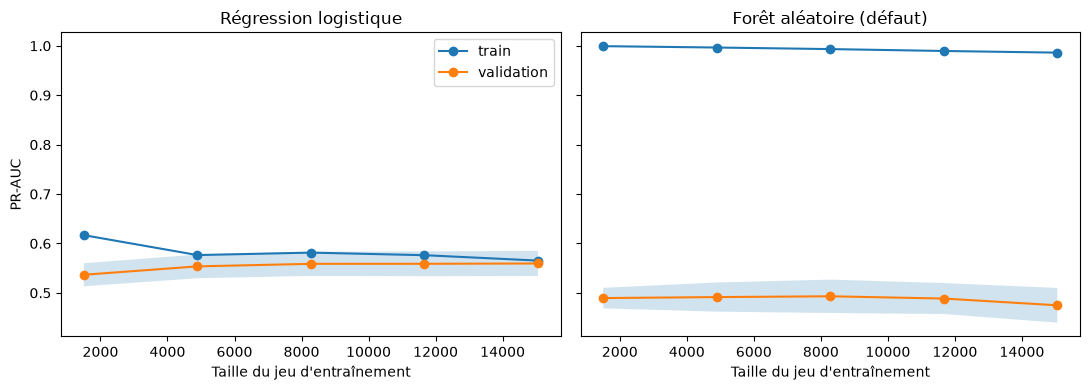

In [5]:
logreg = pipe(LogisticRegression(max_iter=2000))
rf = pipe(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (nom, m) in zip(axes, [("Régression logistique", logreg), ("Forêt aléatoire (défaut)", rf)]):
    sizes, tr, va = learning_curve(m, X_train, y_train, cv=cv, scoring="average_precision",
                                   train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1)
    print(nom, "| train :", tr.mean(1).round(3), "| val :", va.mean(1).round(3))
    ax.plot(sizes, tr.mean(1), "o-", label="train")
    ax.plot(sizes, va.mean(1), "o-", label="validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_title(nom); ax.set_xlabel("Taille du jeu d'entraînement")
axes[0].set_ylabel("PR-AUC"); axes[0].legend()
plt.tight_layout(); plt.savefig(FIGURES / "03_learning_curves.png", dpi=120); plt.show()

     train     val  erreur_type
1   0.9862  0.4757       0.0180
2   0.8478  0.5501       0.0165
5   0.7109  0.5700       0.0148
10  0.6555  0.5734       0.0149
20  0.6196  0.5726       0.0144
50  0.5875  0.5656       0.0143


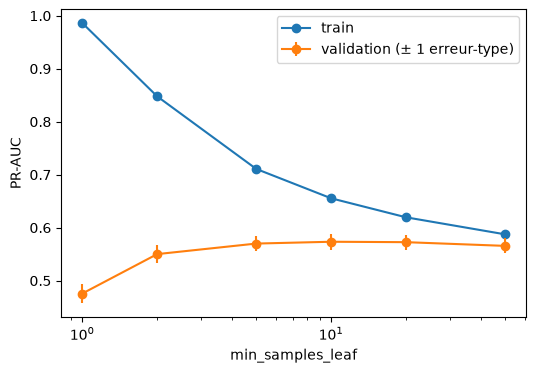

Meilleur : min_samples_leaf=10 (0.5734) | seuil 1-SE = 0.5586
Valeur retenue (règle d'une erreur-type) : 50


In [6]:
leaf = [1, 2, 5, 10, 20, 50]
tr, va = validation_curve(rf, X_train, y_train, cv=cv, scoring="average_precision",
                          param_name="randomforestclassifier__min_samples_leaf",
                          param_range=leaf, n_jobs=-1)
moy, se = va.mean(1), va.std(1, ddof=1) / np.sqrt(va.shape[1])
print(pd.DataFrame({"train": tr.mean(1), "val": moy, "erreur_type": se}, index=leaf).round(4))

plt.figure(figsize=(6, 4))
plt.plot(leaf, tr.mean(1), "o-", label="train")
plt.errorbar(leaf, moy, yerr=se, fmt="o-", label="validation (± 1 erreur-type)")
plt.xscale("log"); plt.xlabel("min_samples_leaf"); plt.ylabel("PR-AUC"); plt.legend(); plt.show()

# Règle d'une erreur-type : le modèle le plus régularisé (plus grand min_samples_leaf)
# dont le score reste >= meilleur score - 1 erreur-type du meilleur
best = moy.argmax()
seuil_1se = moy[best] - se[best]
leaf_retenu = int(max(l for l, v in zip(leaf, moy) if v >= seuil_1se))
print(f"Meilleur : min_samples_leaf={leaf[best]} ({moy[best]:.4f}) | seuil 1-SE = {seuil_1se:.4f}")
print("Valeur retenue (règle d'une erreur-type) :", leaf_retenu)

Q5.4 — Régression logistique : le train et la validation arrivent tous les deux vers 0,56 et ne bougent plus. Ajouter des données n'aiderait pas, c'est le modèle qui est limité.
Forêt par défaut : grand écart entre train (0,99) et validation (0,48), et ça ne s'améliore pas avec plus de données. Il vaut mieux la régulariser (Q5.5).

Q5.5 — PR-AUC selon `min_samples_leaf` :

| min_samples_leaf | 1 | 2 | 5 | 10 | 20 | 50 |
|---|---|---|---|---|---|---|
| Train | 0,986 | 0,848 | 0,711 | 0,656 | 0,620 | 0,588 |
| Validation | 0,476 | 0,550 | 0,570 | 0,573 | 0,573 | 0,566 |

- 1–2 : surapprentissage (gros écart).
- 5–20 : meilleure validation (0,573 à 10).
- 50 : train et validation se rapprochent, la validation baisse un peu.

Avec la règle d'une erreur-type (seuil 0,5586), je prends la valeur la plus simple qui reste au-dessus : `min_samples_leaf = 50`. Ce paramètre oblige chaque feuille à avoir au moins k personnes, donc l'arbre ne peut pas apprendre par cœur.

Étape 6 · Méthodes d'ensemble (mêmes plis)

In [7]:
modeles = {
    "Random Forest": pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf_retenu,
                                                 n_jobs=-1, random_state=RANDOM_STATE)),
    "HistGB": pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    "XGBoost": pipe(XGBClassifier(random_state=RANDOM_STATE)),
    "LightGBM": pipe(LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)),
    # catégories natives, sans pipeline ; un TUPLE (une liste ne se clone pas avec sklearn 1.9)
    "CatBoost natif": CatBoostClassifier(cat_features=tuple(CAT_COLS), verbose=0,
                                         random_seed=RANDOM_STATE, allow_writing_files=False),
}
for nom, m in modeles.items():
    evaluer(nom, m)
    print(f"{nom:15s} PR-AUC {resultats[nom]['test_pr_auc'].mean():.4f}")

Random Forest   PR-AUC 0.5655


HistGB          PR-AUC 0.5678


XGBoost         PR-AUC 0.5442


LightGBM        PR-AUC 0.5650


CatBoost natif  PR-AUC 0.5821


In [8]:
ens = ["LogReg avec mes variables"] + list(modeles)
rapport(ens)

,PR-AUC val,PR-AUC train,ROC-AUC val,Brier val,Accuracy val,Temps fit (s)
model,,,,,,
LogReg avec mes variables,0.559 ± 0.028,0.565,0.849 ± 0.010,0.087 ± 0.003,0.885 ± 0.005,0.48
Random Forest,0.566 ± 0.032,0.588,0.854 ± 0.013,0.088 ± 0.003,0.883 ± 0.003,1.76
HistGB,0.568 ± 0.028,0.669,0.857 ± 0.012,0.086 ± 0.003,0.885 ± 0.005,0.97
XGBoost,0.544 ± 0.024,0.792,0.845 ± 0.010,0.090 ± 0.003,0.882 ± 0.004,0.97
LightGBM,0.565 ± 0.028,0.710,0.855 ± 0.011,0.086 ± 0.003,0.886 ± 0.005,0.56
CatBoost natif,0.582 ± 0.027,0.661,0.863 ± 0.011,0.084 ± 0.003,0.889 ± 0.004,61.55


In [9]:
# Q6.2 : comparaison pli par pli (les plis sont identiques pour tous les modèles)
pr = pd.DataFrame({n: resultats[n]["test_pr_auc"] for n in ens},
                  index=[f"pli {i+1}" for i in range(cv.get_n_splits())])
print(pr.round(3), "\n")
ref = pr.mean().idxmax()
diff = pr.drop(columns=ref).sub(pr[ref], axis=0)
print(f"Écart à {ref}, pli par pli :")
print(diff.round(4), "\n")
print(pd.DataFrame({"moyenne": diff.mean(), "écart-type": diff.std(ddof=1),
                    f"plis où {ref} gagne": (diff < 0).sum()}).round(4))

       LogReg avec mes variables  Random Forest  HistGB  XGBoost  LightGBM  CatBoost natif
pli 1                      0.551          0.565   0.567    0.549     0.569           0.586
pli 2                      0.590          0.594   0.584    0.556     0.580           0.594
pli 3                      0.574          0.582   0.584    0.558     0.579           0.594
pli 4                      0.515          0.511   0.519    0.501     0.515           0.534
pli 5                      0.568          0.575   0.585    0.556     0.582           0.602 

Écart à CatBoost natif, pli par pli :
       LogReg avec mes variables  Random Forest  HistGB  XGBoost  LightGBM
pli 1                    -0.0347        -0.0210 -0.0190  -0.0371   -0.0173
pli 2                    -0.0047        -0.0002 -0.0103  -0.0384   -0.0143
pli 3                    -0.0204        -0.0118 -0.0102  -0.0360   -0.0154
pli 4                    -0.0194        -0.0232 -0.0155  -0.0329   -0.0190
pli 5                    -0.0340       

Q6.1 — Mêmes plis pour tous :

| Modèle | PR-AUC val | PR-AUC train | ROC-AUC val | Brier val | Temps fit (s) |
|---|---|---|---|---|---|
| LogReg (référence) | 0,559 ± 0,028 | 0,565 | 0,849 ± 0,010 | 0,087 ± 0,003 | 0,5 |
| Random Forest (leaf=50) | 0,566 ± 0,032 | 0,588 | 0,854 ± 0,013 | 0,088 ± 0,003 | 1,8 |
| HistGB | 0,568 ± 0,028 | 0,669 | 0,857 ± 0,012 | 0,086 ± 0,003 | 1,0 |
| XGBoost | 0,544 ± 0,024 | 0,792 | 0,845 ± 0,010 | 0,090 ± 0,003 | 1,0 |
| LightGBM | 0,565 ± 0,028 | 0,710 | 0,855 ± 0,011 | 0,086 ± 0,003 | 0,6 |
| CatBoost natif | 0,582 ± 0,027 | 0,661 | 0,863 ± 0,011 | 0,084 ± 0,003 | 61,6 |

Q6.2 — En regardant seulement les moyennes, non : les écarts sont petits par rapport aux variations entre plis. Mais pli par pli, CatBoost gagne les 5 plis contre tous les autres modèles, d'environ 0,015. Donc CatBoost est un peu meilleur, mais de peu, et 5 plis ce n'est pas beaucoup pour en être sûr. XGBoost par défaut est le moins bon.

Q6.3 — Écart train − validation : XGBoost 0,25, LightGBM 0,15, HistGB 0,10, CatBoost 0,08, forêt 0,02. XGBoost surapprend le plus : par défaut ses arbres sont trop libres. Le bagging (forêt) réduit la variance, le boosting réduit le biais, mais sans régularisation le boosting finit par apprendre le bruit.

Q6.4 — CatBoost est le meilleur sur toutes les métriques (PR-AUC 0,582). Mais il met environ 62 s, contre 0,5 à 2 s pour les autres : 60 fois plus lent pour seulement +0,015. Son avantage est de bien gérer les catégories sans fuite de la cible. Ici il y a peu de catégories, donc ça aide peu. Attention : CatBoost n'utilise pas mes variables construites, donc la comparaison n'est pas parfaite.

Q6.5 — Je choisis HistGradientBoosting. Il est presque aussi bon que CatBoost (0,568 contre 0,582), il est rapide (1 s), il marche directement avec scikit-learn et il reste de la marge pour le régler. CatBoost est trop lent pour la suite, je le garde juste comme référence.

In [10]:
# Décisions transmises aux notebooks suivants
DECISIONS.parent.mkdir(parents=True, exist_ok=True)
dec = json.loads(DECISIONS.read_text()) if DECISIONS.exists() else {}
dec["rf_min_samples_leaf"] = leaf_retenu
dec["histgb_defaut_pr_auc"] = [float(resultats["HistGB"]["test_pr_auc"].mean()),
                               float(resultats["HistGB"]["test_pr_auc"].std(ddof=1))]
DECISIONS.write_text(json.dumps(dec, indent=2))
dec

{'rf_min_samples_leaf': 50,
 'histgb_defaut_pr_auc': [0.5678159814594989, 0.028421765960187053]}